# Oasis Infobyte Internship — Level 2, Task 02

## Wine Quality Prediction

### Objective

The objective of this project is to analyse the physicochemical properties of red wine and develop machine learning classification models to predict wine quality categories.

The project uses the Wine Quality dataset and compares three classification algorithms:

- Random Forest Classifier
- Stochastic Gradient Descent (SGD) Classifier
- Support Vector Classifier (SVC)

The workflow includes data inspection, exploratory data analysis, class imbalance analysis, feature engineering, model training, evaluation, feature importance analysis, and model comparison.

### Technology Stack

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.

In [39]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

In [40]:
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [41]:
# Loading the Dataset
# Google Colab
from google.colab import files
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Saving winequality-red.csv to winequality-red (2).csv
Dataset loaded successfully!
Dataset shape: (1599, 12)


## 1. Dataset Inspection

The dataset contains measurements of red wine, including acidity, residual sugar, chlorides, density, pH, sulphates, and alcohol content. The `quality` column represents the wine quality score and is the target variable.

Initial inspection helps us understand the dataset dimensions, column names, data types, missing values, and duplicate records.

In [42]:
print("First five rows:")
display(df.head())
print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))
print("Total missing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("\nStatistical summary:")
display(df.describe().T)

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Number of rows: 1599
Number of columns: 12

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values in each column:


,Missing Values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Total missing values: 0
Exact duplicate rows: 240

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [43]:
# Handle missing values
df = df.dropna().copy()
print("Rows before duplicate removal:", len(df))

# Remove exact duplicate records
df = df.drop_duplicates().copy()
print("Rows after duplicate removal:", len(df))
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

Rows before duplicate removal: 1599
Rows after duplicate removal: 1359
Remaining missing values: 0
Remaining duplicate rows: 0


## 2. Descriptive Statistical Analysis

Descriptive statistics help us understand the central tendency and variability of the chemical properties. The mean, median, standard deviation, minimum, and maximum values provide an overview of the measurements and help identify features with different scales.

In [44]:
display(df.describe().T)
print("\nMedian values:")
display(df.median(numeric_only=True).to_frame("Median"))
print("\nMode values:")
display(df.mode().iloc[0].to_frame("Mode"))

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000



Median values:


,Median
fixed acidity,7.9000
volatile acidity,0.5200
citric acid,0.2600
residual sugar,2.2000
chlorides,0.0790
free sulfur dioxide,14.0000
total sulfur dioxide,38.0000
density,0.9967
pH,3.3100
sulphates,0.6200



Mode values:


,Mode
fixed acidity,7.2000
volatile acidity,0.5000
citric acid,0.0000
residual sugar,2.0000
chlorides,0.0800
free sulfur dioxide,6.0000
total sulfur dioxide,28.0000
density,0.9968
pH,3.3000
sulphates,0.5400


Wine quality counts:


,Number of Wines
quality,
3,10
4,53
5,577
6,535
7,167
8,17


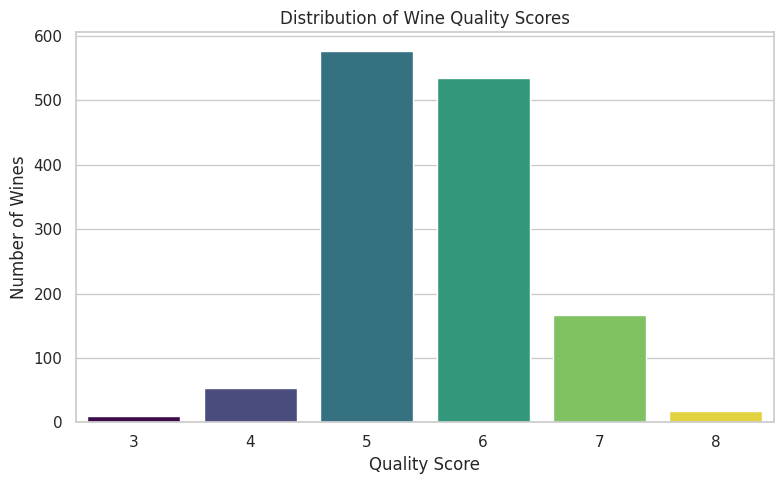

In [45]:
quality_counts = df["quality"].value_counts().sort_index()
print("Wine quality counts:")
display(quality_counts.to_frame("Number of Wines"))
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="quality",hue="quality",order=sorted(df["quality"].unique()),palette="viridis",legend=False)
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distribution of each physicochemical feature. Histograms can reveal skewness, concentration of values, and possible outliers. These plots help identify the characteristics of the dataset before model training.

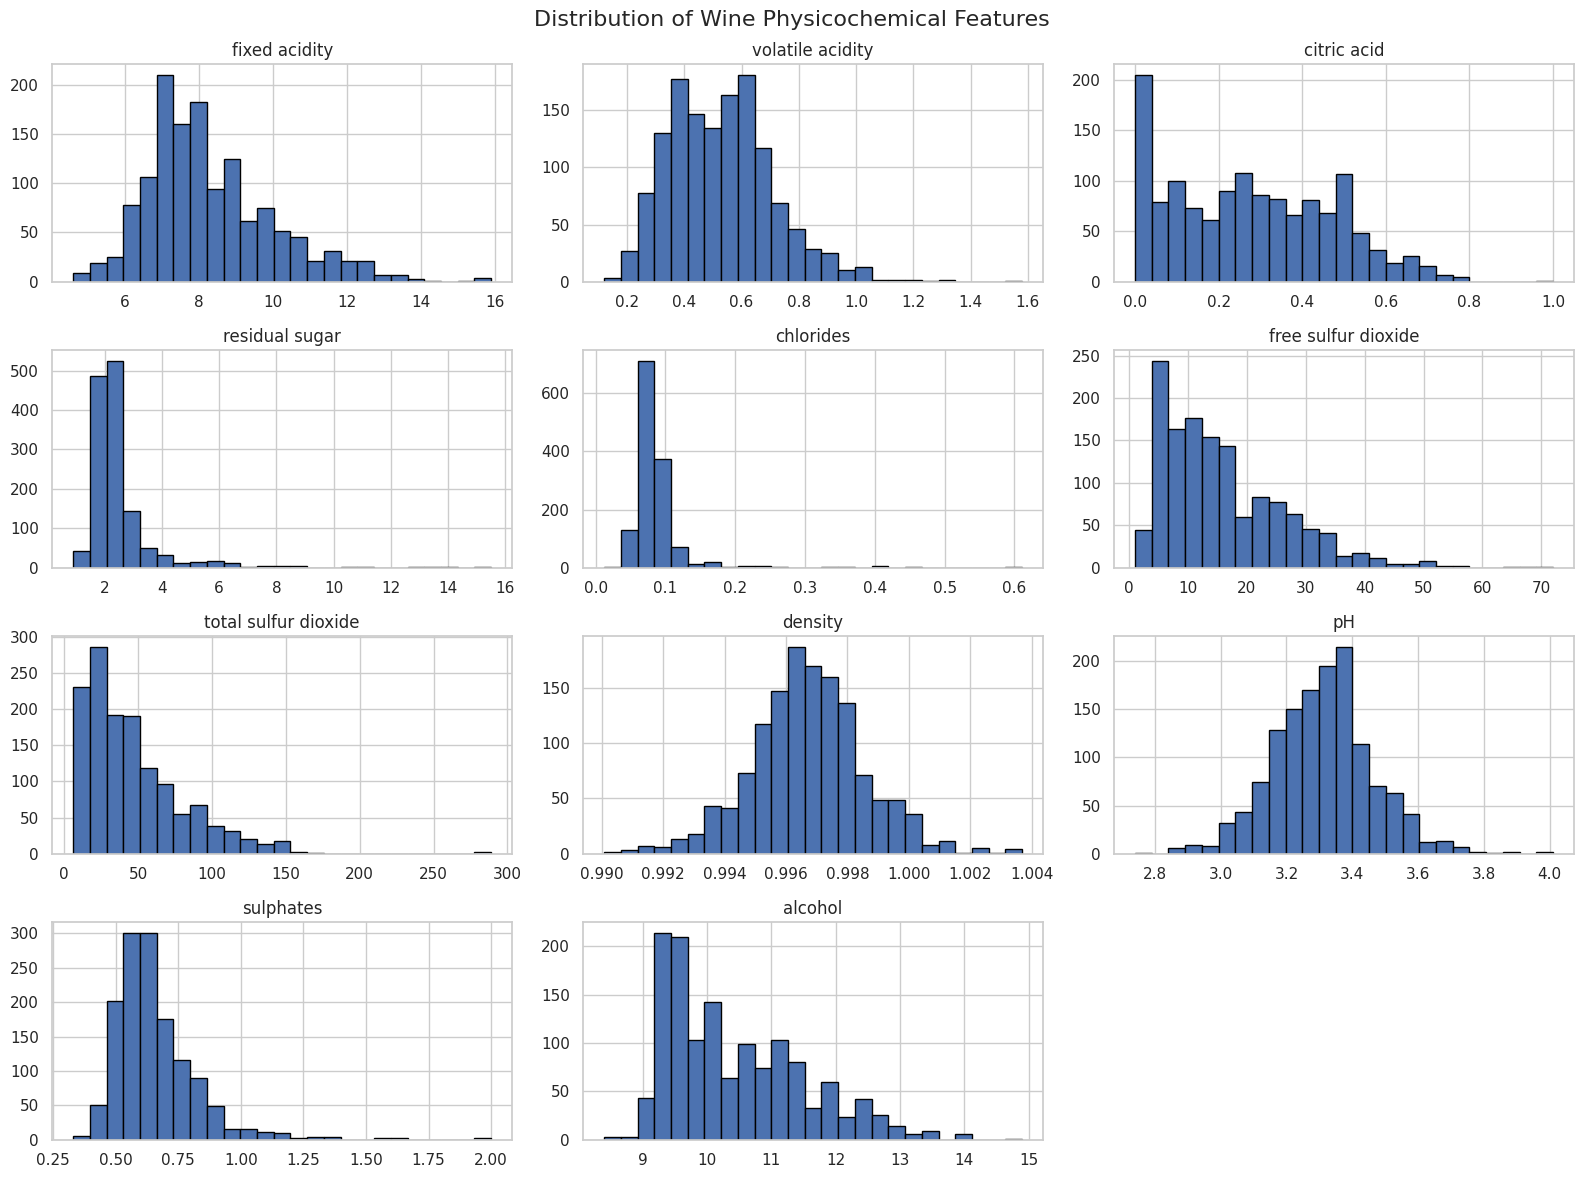

In [46]:
feature_columns = [column for column in df.columns if column != "quality"]
df[feature_columns].hist(figsize=(16, 12),bins=25,edgecolor="black")
plt.suptitle("Distribution of Wine Physicochemical Features",fontsize=16)
plt.tight_layout()
plt.show()

## 4. Correlation Analysis

Correlation measures the strength and direction of a linear relationship between numerical variables. A positive correlation means that two variables tend to increase together, while a negative correlation means that one tends to decrease as the other increases.

The correlation heatmap helps identify features associated with wine quality. Correlation does not necessarily imply causation.

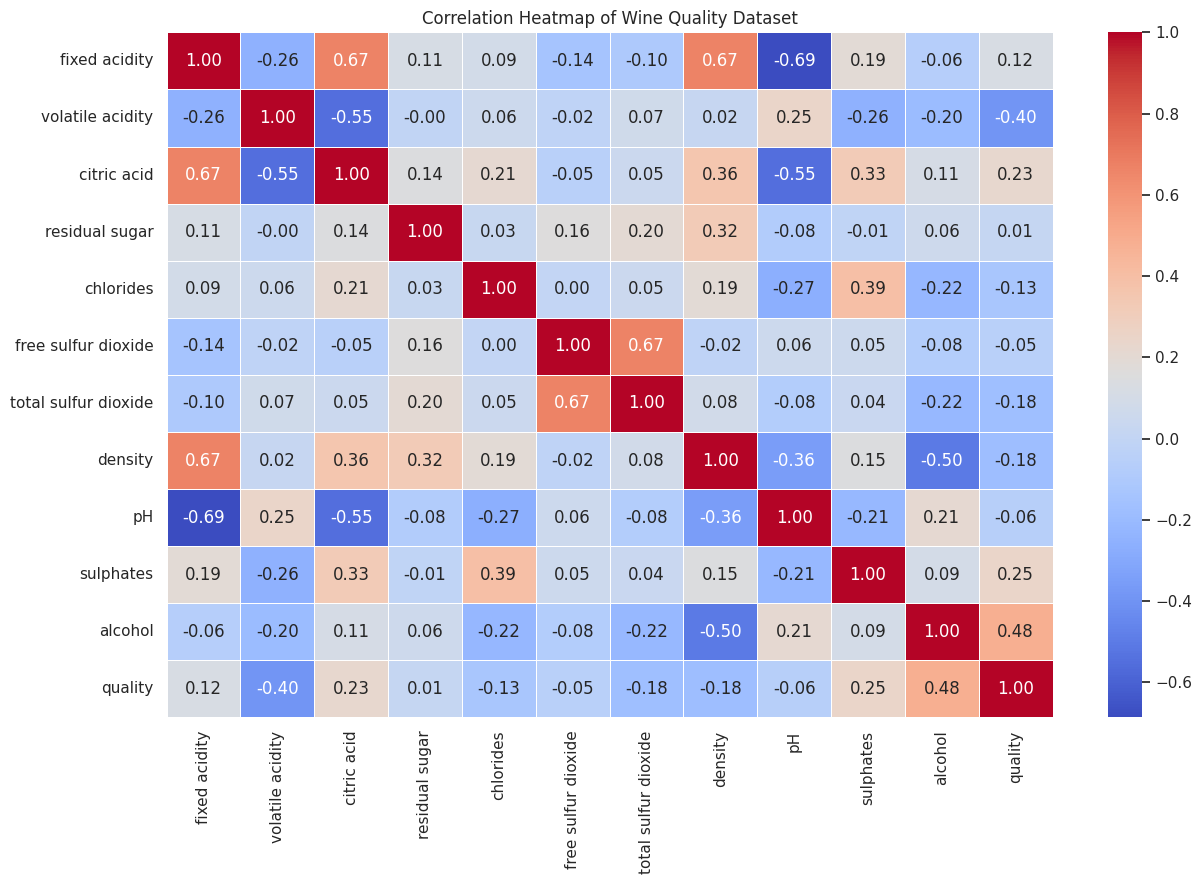

Correlation with wine quality:


,Correlation with Quality
alcohol,0.480343
sulphates,0.248835
citric acid,0.228057
fixed acidity,0.119024
residual sugar,0.013640
free sulfur dioxide,-0.050463
pH,-0.055245
chlorides,-0.130988
total sulfur dioxide,-0.177855
density,-0.184252


In [47]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("Correlation Heatmap of Wine Quality Dataset")
plt.tight_layout()
plt.show()
print("Correlation with wine quality:")
display(correlation_matrix["quality"].drop("quality").sort_values(ascending=False).to_frame("Correlation with Quality"))

## 5. Feature Engineering and Class Imbalance

The original `quality` variable contains integer scores. For this classification task, the scores are grouped into three categories:

- **Low:** quality score less than or equal to 5
- **Medium:** quality score equal to 6
- **High:** quality score greater than or equal to 7

This grouping simplifies the prediction task while retaining an intuitive interpretation of the quality levels. The groups are not equally represented, so class imbalance must be considered during training and evaluation.

Quality category counts:


,Number of Wines
quality_category,
Low,640
Medium,535
High,184



Quality category percentages:


,Percentage
quality_category,
Low,47.09
Medium,39.37
High,13.54


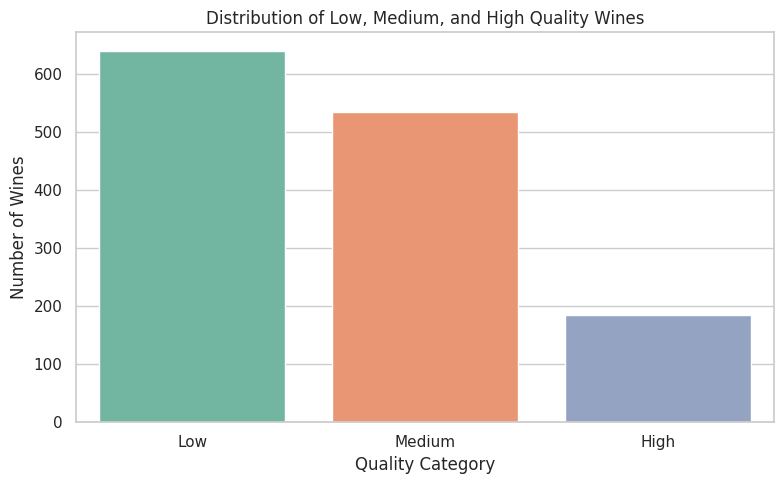

In [48]:
df["quality_category"] = pd.cut(df["quality"],bins=[-np.inf, 5, 6, np.inf],labels=["Low", "Medium", "High"])
category_order = ["Low", "Medium", "High"]
print("Quality category counts:")
display(df["quality_category"].value_counts().reindex(category_order).to_frame("Number of Wines"))

print("\nQuality category percentages:")
display(
    (df["quality_category"].value_counts(normalize=True).reindex(category_order) * 100).round(2).to_frame("Percentage")
)

plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="quality_category",hue="quality_category",order=category_order,palette="Set2",legend=False)
plt.title("Distribution of Low, Medium, and High Quality Wines")
plt.xlabel("Quality Category")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

## 6. Feature Selection

The 11 physicochemical measurements are used as input features (`X`). The newly created `quality_category` is used as the target (`y`). The original numerical `quality` column is excluded from the input features because it was used to create the target categories. Including it would cause target leakage and make the evaluation invalid.

In [49]:
X = df[feature_columns].copy()
y = df["quality_category"].astype(str)
print("Input feature columns:")
print(X.columns.tolist())
print("\nTarget variable: quality_category")
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Input feature columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Target variable: quality_category
Feature matrix shape: (1359, 11)
Target shape: (1359,)

Target classes:
quality_category
Low       640
Medium    535
High      184
Name: count, dtype: int64


## 7. Train-Test Split

The dataset is divided into 80% training data and 20% testing data. The training data is used to fit the classifiers, while the testing data evaluates their performance on unseen samples.

Stratification is used to preserve approximately the same proportions of Low, Medium, and High quality wines in both sets.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("\nTraining class distribution:")
display(y_train.value_counts(normalize=True).reindex(category_order).to_frame("Training Proportion"))
print("\nTesting class distribution:")
display(y_test.value_counts(normalize=True).reindex(category_order).to_frame("Testing Proportion"))

Training samples: 1087
Testing samples: 272

Training class distribution:


,Training Proportion
quality_category,
Low,0.471021
Medium,0.393744
High,0.135235



Testing class distribution:


,Testing Proportion
quality_category,
Low,0.470588
Medium,0.393382
High,0.136029


## 8. Classification Models

Three classifiers are trained and compared.

1. **Random Forest:** Combines predictions from multiple decision trees and can capture nonlinear relationships.
2. **SGD Classifier:** Uses stochastic gradient descent to learn classification boundaries. Feature scaling is important for this model.
3. **Support Vector Classifier (SVC):** Finds decision boundaries between classes. The RBF kernel can model nonlinear relationships, and feature scaling is important.

Balanced class weights are used to give greater consideration to underrepresented classes. Standardisation for SGD and SVC is placed inside a pipeline so the scaler is fitted only on the training data.

In [51]:
random_forest = RandomForestClassifier(n_estimators=300,random_state=42,class_weight="balanced",n_jobs=-1)
sgd_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SGDClassifier(loss="log_loss",max_iter=3000,tol=1e-3,random_state=42,class_weight="balanced"))
])

svc_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf",class_weight="balanced"))
])

models = {"Random Forest": random_forest,"SGD Classifier": sgd_model,"SVC": svc_model}
print("All three classification models are initialised.")

All three classification models are initialised.


In [52]:
for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(model_name, "trained successfully.")

Random Forest trained successfully.
SGD Classifier trained successfully.
SVC trained successfully.


## 9. Model Evaluation

Each classifier is evaluated using the test dataset.

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Proportion of predicted class members that are correct.
- **Recall:** Proportion of actual class members correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **Classification report:** Shows precision, recall, F1-score, and support for each class.
- **Confusion matrix:** Shows correct predictions and the classes that are confused with one another.

Macro-averaged F1-score is included because it gives equal weight to each class, rather than allowing the largest class to dominate the overall score.


MODEL: Random Forest
              precision    recall  f1-score   support

         Low       0.71      0.70      0.70       128
      Medium       0.53      0.64      0.58       107
        High       0.78      0.38      0.51        37

    accuracy                           0.63       272
   macro avg       0.67      0.57      0.60       272
weighted avg       0.65      0.63      0.63       272

Confusion Matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,89,39,0
Actual Medium,35,68,4
Actual High,2,21,14


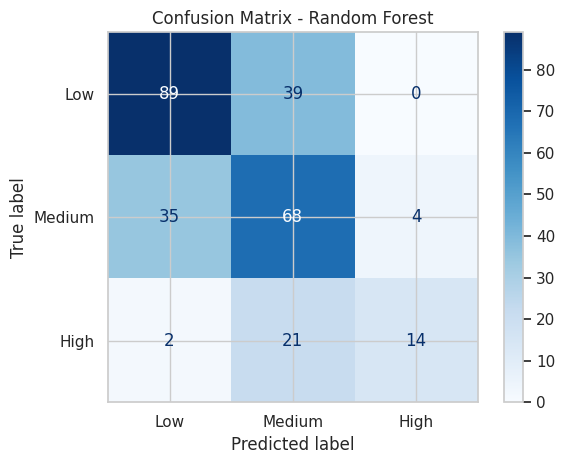


MODEL: SGD Classifier
              precision    recall  f1-score   support

         Low       0.72      0.60      0.66       128
      Medium       0.50      0.32      0.39       107
        High       0.28      0.73      0.40        37

    accuracy                           0.51       272
   macro avg       0.50      0.55      0.48       272
weighted avg       0.57      0.51      0.52       272

Confusion Matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,77,26,25
Actual Medium,28,34,45
Actual High,2,8,27


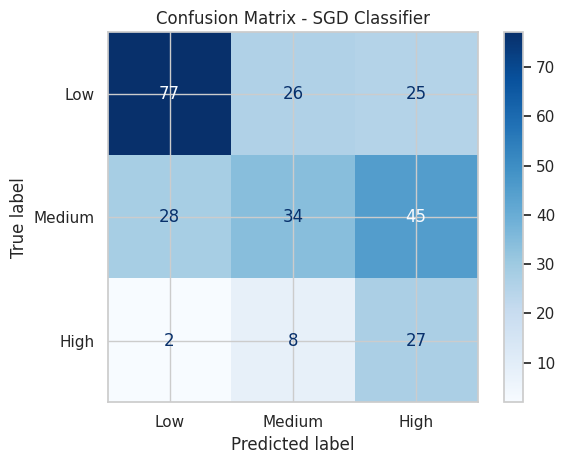


MODEL: SVC
              precision    recall  f1-score   support

         Low       0.70      0.69      0.70       128
      Medium       0.50      0.44      0.47       107
        High       0.49      0.70      0.58        37

    accuracy                           0.59       272
   macro avg       0.56      0.61      0.58       272
weighted avg       0.59      0.59      0.59       272

Confusion Matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,88,38,2
Actual Medium,35,47,25
Actual High,2,9,26


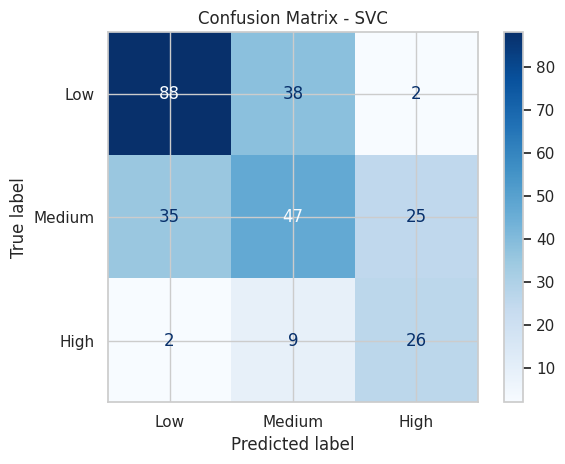

In [53]:
results = []
predictions = {}
class_labels = ["Low", "Medium", "High"]

for model_name, model in models.items():

    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred
    accuracy = accuracy_score(y_test, y_pred)
    macro_precision = precision_score(y_test, y_pred,labels=class_labels,average="macro",zero_division=0)
    macro_recall = recall_score(y_test, y_pred,labels=class_labels,average="macro",zero_division=0)
    macro_f1 = f1_score(y_test, y_pred,labels=class_labels,average="macro",zero_division=0)
    weighted_f1 = f1_score(y_test, y_pred,labels=class_labels,average="weighted",zero_division=0)
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1-score": macro_f1,
        "Weighted F1-score": weighted_f1
    })
    print("\n", "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)
    print(classification_report(y_test,y_pred,labels=class_labels,zero_division=0))
    cm = confusion_matrix(y_test,y_pred,labels=class_labels)
    print("Confusion Matrix:")
    display(pd.DataFrame(cm,index=[f"Actual {c}" for c in class_labels],columns=[f"Predicted {c}" for c in class_labels]))
    ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_labels).plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

## 10. Random Forest Feature Importance

Random Forest provides a feature-importance score for each input feature. These scores estimate how useful the features were for reducing impurity across the fitted trees.

The chart ranks the physicochemical properties according to their importance in this model. These values describe model behaviour and should not be interpreted as proof of causation.

,Feature,Importance
10,alcohol,0.177364
9,sulphates,0.127946
1,volatile acidity,0.102377
7,density,0.087843
6,total sulfur dioxide,0.087152
2,citric acid,0.079701
4,chlorides,0.073987
8,pH,0.070680
0,fixed acidity,0.068632
3,residual sugar,0.064287


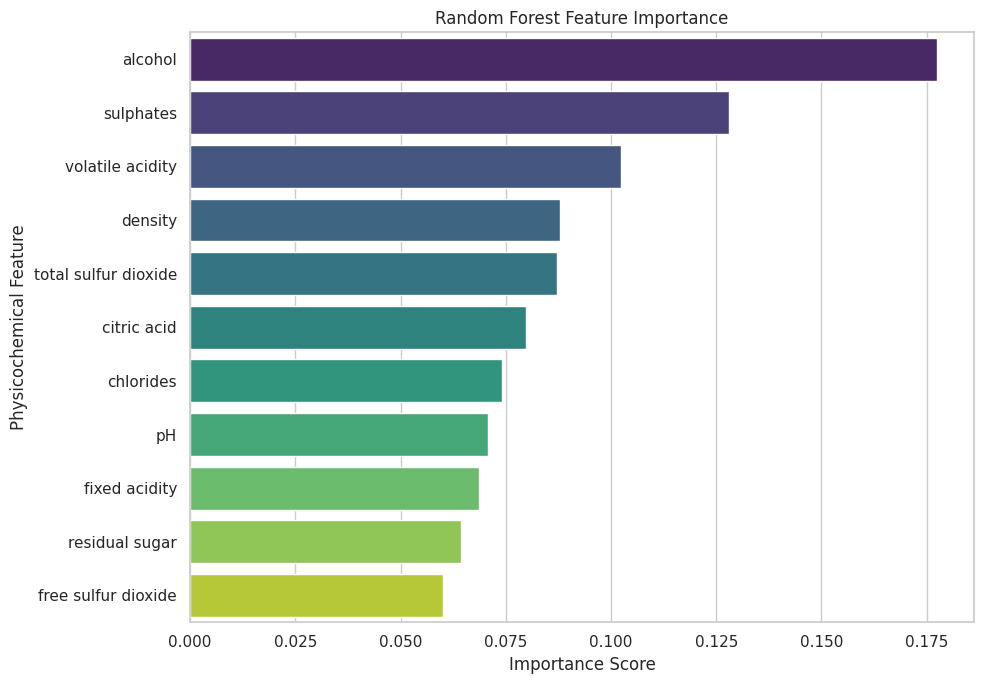

In [54]:
feature_importance = pd.DataFrame({"Feature": X.columns,"Importance": random_forest.feature_importances_}).sort_values(by="Importance",ascending=False)
display(feature_importance)
plt.figure(figsize=(10, 7))
sns.barplot(data=feature_importance,x="Importance",y="Feature",hue="Feature",palette="viridis",legend=False)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Physicochemical Feature")
plt.tight_layout()
plt.show()

## 11. Model Performance Comparison

The performance of Random Forest, SGD Classifier, and SVC is compared using accuracy, macro precision, macro recall, macro F1-score, and weighted F1-score.

The macro F1-score is used as the primary comparison metric because the quality categories are imbalanced. Accuracy is also reported, but it should not be used alone to select the final model.

Model comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score
0,Random Forest,0.6287,0.6718,0.5697,0.5962,0.6267
1,SVC,0.5919,0.5649,0.6098,0.5804,0.5899
2,SGD Classifier,0.5074,0.4993,0.5497,0.4823,0.5161


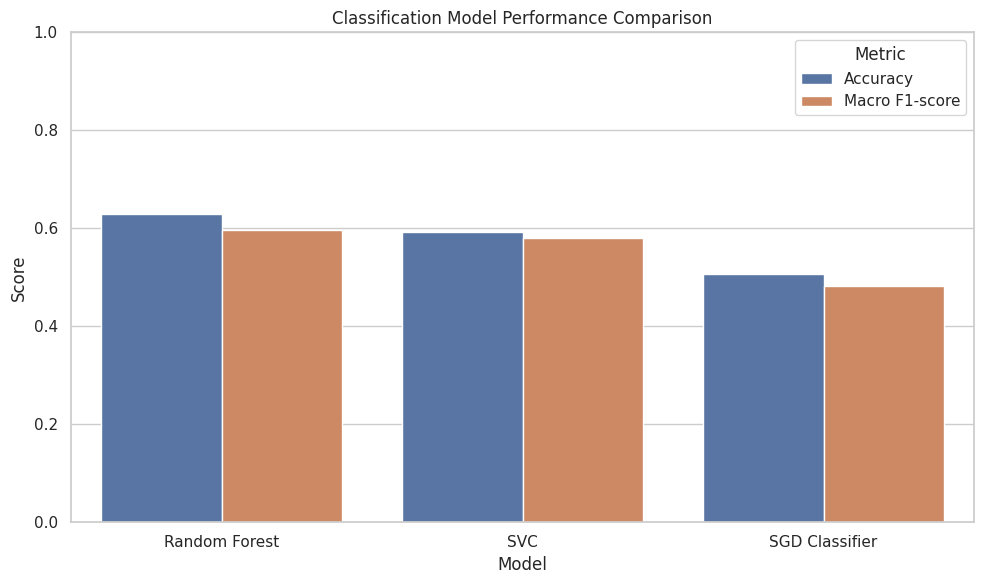

Comparison and feature-importance tables saved.


In [55]:
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by="Macro F1-score",ascending=False).reset_index(drop=True)
print("Model comparison:")
display(comparison_df.round(4))
plt.figure(figsize=(10, 6))
comparison_plot = comparison_df.melt(id_vars="Model",value_vars=["Accuracy", "Macro F1-score"],var_name="Metric",value_name="Score")
sns.barplot(data=comparison_plot,x="Model",y="Score",hue="Metric")
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()
comparison_df.to_csv("wine_quality_model_comparison.csv",index=False)
feature_importance.to_csv("wine_quality_feature_importance.csv",index=False)
print("Comparison and feature-importance tables saved.")

### Interpretation of Model Comparison

The comparison table shows the test-set performance of all three classifiers. The best model should be selected by considering macro F1-score alongside accuracy, precision, recall, and the confusion matrix.

A model with high accuracy but poor recall for the High-quality class may not be the best choice. The classification reports and confusion matrices help reveal such weaknesses.

The actual results should be interpreted after running the notebook, rather than assuming a particular model will perform best.

## 12. Conclusion

This project applies machine learning classification to the Wine Quality dataset. The workflow includes dataset inspection, missing-value checks, descriptive statistics, exploratory visualisation, correlation analysis, quality-category grouping, and a stratified train-test split.

Random Forest, SGD Classifier, and Support Vector Classifier are trained and evaluated using accuracy, classification reports, confusion matrices, and F1-scores. Random Forest feature importance is also examined to understand which physicochemical properties contribute most to the fitted model.

The final model should be selected based on the measured test-set performance, with particular attention to macro F1-score because the quality categories are imbalanced. Further improvements could include hyperparameter tuning, cross-validation, and testing alternative quality-group definitions.

The model predicts the categories defined in this project; it does not directly predict the original numerical quality score.

In [56]:
best_model_row = comparison_df.iloc[0]
print("FINAL MODEL COMPARISON")
print("-" * 40)
print("Best model by Macro F1-score:",best_model_row["Model"])
print("Accuracy:",round(best_model_row["Accuracy"], 4))
print("Macro F1-score:",round(best_model_row["Macro F1-score"], 4))
print("\nFull comparison:")
display(comparison_df.round(4))

FINAL MODEL COMPARISON
----------------------------------------
Best model by Macro F1-score: Random Forest
Accuracy: 0.6287
Macro F1-score: 0.5962

Full comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score
0,Random Forest,0.6287,0.6718,0.5697,0.5962,0.6267
1,SVC,0.5919,0.5649,0.6098,0.5804,0.5899
2,SGD Classifier,0.5074,0.4993,0.5497,0.4823,0.5161
